# TP3 · Clasificación de etapas de adopción de IA

**Pregunta:** ¿Se puede clasificar la etapa de adopción (none, pilot, partial, full) de una empresa y trimestre a partir del contexto y señales observadas de uso y capacitación?

## A. Marco experimental

ai_adoption_stage resulta útil para clasificar niveles categóricos de adopción y se deriva por tramos de ai_adoption_rate; por eso excluimos esa tasa y years_using_ai. Incluimos num_ai_tools_used y ai_training_hours como señales observables del mismo período, pero por su cercanía al objetivo comparamos también un modelo que no las utiliza.

La partición 80/20 separa empresas completas con StratifiedGroupKFold y semilla 2026: conserva aproximadamente las proporciones de clase y evita empresas compartidas entre train y prueba. La validación interna usa cinco folds estratificados y agrupados por empresa.

In [1]:
import os
import warnings
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 1)
warnings.filterwarnings("ignore", message="Could not find the number of physical cores.*", category=UserWarning, module="joblib.externals.loky.backend.context")

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate, cross_val_predict, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, accuracy_score, precision_score, recall_score,
    cohen_kappa_score, make_scorer, silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, roc_curve, auc,
    precision_recall_curve, average_precision_score,
)
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

SEMILLA = 2026
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR_BASE, COLOR_LINEA = "#2b5c8f", "#d95f02"

DIRECTORIO = Path.cwd().resolve()
PROYECTO = DIRECTORIO if DIRECTORIO.name == "proyecto_equipo" else DIRECTORIO / "proyecto_equipo"
if not (PROYECTO / "notebooks").is_dir():
    raise FileNotFoundError("Abrí Jupyter desde la raíz del repositorio o desde proyecto_equipo")
RUTA_PARQUET = PROYECTO / "datos" / "derivados" / "ai_company_adoption_limpio.parquet"
if not RUTA_PARQUET.exists():
    raise FileNotFoundError("Ejecutá primero 02_limpieza_ai.ipynb para generar el Parquet limpio")
SALIDAS = PROYECTO / "salidas"
SALIDAS.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(RUTA_PARQUET)
assert df.shape == (150_000, 43), f"Dimensiones inesperadas: {df.shape}"
print(f"Dataset: {len(df):,} filas | {df['company_id'].nunique():,} empresas | datos derivados del proyecto")

Dataset: 150,000 filas | 10,000 empresas | datos derivados del proyecto


## B. Modelos

La regresión logística multinomial es el baseline recomendado; Dummy prior aporta un piso. Se comparan además árbol, Gaussian Naive Bayes y Random Forest, que permite contrastar el ensamble con modelos individuales.

Se ponderan las clases minoritarias cuando el estimador lo admite. Los hiperparámetros se ajustan en train y las transformaciones permanecen dentro de los pipelines.

In [2]:
target_col = "ai_adoption_stage"
orden_etapas = ["none", "pilot", "partial", "full"]
y = df[target_col].astype("category").cat.reorder_categories(orden_etapas, ordered=True)

# Objetivo y predictores. La etiqueta se deriva de ai_adoption_rate, por eso se excluye
# tanto la tasa como years_using_ai y las métricas contemporáneas de impacto.
cols_cat = ["country", "industry"]
cols_log = ["num_employees", "annual_revenue_usd_millions"]
cols_std = ["company_age", "survey_year", "num_ai_tools_used", "ai_training_hours"]
predictores = cols_cat + cols_log + cols_std
X = df[predictores].copy()
grupos = df["company_id"].astype("string")

# Partición 80/20 que mantiene juntas las filas por empresa y aproxima estratificación por clase.
partidor = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
train_idx, test_idx = next(partidor.split(X, y, groups=grupos))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
grupos_train, grupos_test = grupos.iloc[train_idx], grupos.iloc[test_idx]
assert set(grupos_train).isdisjoint(set(grupos_test))

frecuencias = []
for nombre, etiquetas in [("Total", y), ("Entrenamiento", y_train), ("Prueba", y_test)]:
    v = etiquetas.value_counts(normalize=True).reindex(orden_etapas).fillna(0)
    frecuencias.append(pd.DataFrame({"Conjunto": nombre, "Clase": orden_etapas, "Porcentaje (%)": (100*v).round(2).values}))
distribucion = pd.concat(frecuencias, ignore_index=True)
display(distribucion.pivot(index="Clase", columns="Conjunto", values="Porcentaje (%)"))
print(f"Entrenamiento: {len(X_train):,} filas / {grupos_train.nunique():,} empresas")
print(f"Prueba: {len(X_test):,} filas / {grupos_test.nunique():,} empresas; empresas compartidas: 0")

Conjunto,Entrenamiento,Prueba,Total
Clase,,,
full,1.12,1.12,1.12
none,3.46,3.47,3.47
partial,52.54,52.51,52.53
pilot,42.87,42.90,42.88


Entrenamiento: 119,996 filas / 8,000 empresas
Prueba: 30,004 filas / 2,000 empresas; empresas compartidas: 0


In [3]:
def crear_preprocesador(incluir_comportamiento=True):
    prep_log = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("escalar", StandardScaler()),
    ])
    prep_std = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
    ])
    prep_cat = Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    columnas_estandar = cols_std if incluir_comportamiento else ["company_age", "survey_year"]
    return ColumnTransformer([
        ("log", prep_log, cols_log),
        ("std", prep_std, columnas_estandar),
        ("cat", prep_cat, cols_cat),
    ], remainder="drop")

In [4]:
# Pipelines definidos una sola vez; LogisticRegression C=1 es la referencia.
pipe_lr = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", LogisticRegression(C=1.0, max_iter=700, class_weight="balanced", random_state=SEMILLA)),
])
pipe_dummy = Pipeline([("prepro", crear_preprocesador()), ("modelo", DummyClassifier(strategy="prior"))])
# Árbol acotado y hojas grandes para limitar reglas frágiles; class_weight trata el desbalance.
pipe_dt = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=SEMILLA)),
])
pipe_nb = Pipeline([("prepro", crear_preprocesador()), ("modelo", GaussianNB())])
# Random Forest prueba un ensamble bagging; profundidad y hojas controlan complejidad.
pipe_rf = Pipeline([
    ("prepro", crear_preprocesador()),
    ("modelo", RandomForestClassifier(
        n_estimators=100, max_depth=10, min_samples_leaf=20,
        class_weight="balanced", random_state=SEMILLA, n_jobs=1,
    )),
])
modelos_clasif = {
    "Regresión logística (baseline)": pipe_lr,
    "Dummy (prior)": pipe_dummy,
    "Árbol de decisión": pipe_dt,
    "Naive Bayes": pipe_nb,
    "Random Forest (ensamble)": pipe_rf,
}
print("Cinco referencias/modelos definidos; la regresión logística es el baseline y Dummy el piso simple.")

Cinco referencias/modelos definidos; la regresión logística es el baseline y Dummy el piso simple.


## C. Evaluación

Se compara entrenamiento con empresas reservadas y se selecciona por F1 macro de validación cruzada para dar el mismo peso a cada etapa. Kappa y los reportes por clase complementan accuracy; las matrices muestran dónde se equivoca cada modelo.

In [5]:
# Validación cruzada estratificada y agrupada; las filas de una empresa nunca cruzan folds.
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA + 1)
cv_splits = list(cv_grupos.split(X_train, y_train, groups=grupos_train))
scoring_clasif = {
    "Accuracy": "accuracy",
    "Precision macro": make_scorer(precision_score, average="macro", zero_division=0),
    "Recall macro": make_scorer(recall_score, average="macro", zero_division=0),
    "F1 macro": make_scorer(f1_score, average="macro", zero_division=0),
    "F1 ponderado": make_scorer(f1_score, average="weighted", zero_division=0),
    "Kappa": make_scorer(cohen_kappa_score),
}
resultados_cv_tp3 = {}
for nombre, modelo in modelos_clasif.items():
    resultados_cv_tp3[nombre] = cross_validate(
        modelo, X_train, y_train, cv=cv_splits, scoring=scoring_clasif,
        return_train_score=True, n_jobs=1,
    )

# Búsqueda de C para logística con los mismos folds; el test no participa.
# Se amplía la grilla para comprobar si el óptimo deja de quedar en el borde.
grilla_logistica = GridSearchCV(
    pipe_lr,
    param_grid={"modelo__C": [0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]},
    scoring="f1_macro", cv=cv_splits, n_jobs=1, return_train_score=True, refit=True,
)
grilla_logistica.fit(X_train, y_train)
pipe_lr_ajustada = grilla_logistica.best_estimator_
print(f"GridSearchCV logística: C={grilla_logistica.best_params_['modelo__C']}; F1 macro CV de búsqueda={grilla_logistica.best_score_:.3f}")
f1_lr_base = resultados_cv_tp3["Regresión logística (baseline)"]["test_F1 macro"].mean()
print(f"Cambio frente a C=1 en F1 macro CV: {grilla_logistica.best_score_ - f1_lr_base:+.4f}")

# Evaluar la logística ajustada con todas las métricas, incluida Kappa, en los mismos folds.
resultados_cv_tp3["Regresión logística (GridSearchCV)"] = cross_validate(
    pipe_lr_ajustada, X_train, y_train, cv=cv_splits, scoring=scoring_clasif,
    return_train_score=True, n_jobs=1,
)
# Añadir el modelo ajustado al mismo diccionario, sin redefinir los pipelines base.
modelos_clasif["Regresión logística (GridSearchCV)"] = pipe_lr_ajustada

filas_cv_tp3 = []
for nombre, r in resultados_cv_tp3.items():
    fila = {"Modelo": nombre}
    for metrica in ["Accuracy", "Precision macro", "Recall macro", "F1 macro", "F1 ponderado", "Kappa"]:
        vals = r[f"test_{metrica}"]
        tr = r[f"train_{metrica}"]
        fila[f"{metrica} CV (media ± DE)"] = f"{vals.mean():.3f} ± {vals.std(ddof=1):.3f}"
        if metrica == "F1 macro":
            fila["F1 macro CV media"] = vals.mean()
            fila["F1 macro train CV media"] = tr.mean()
            fila["Brecha F1 macro CV"] = tr.mean() - vals.mean()
    fila["Tiempo ajuste CV (s)"] = f"{r['fit_time'].mean():.2f} ± {r['fit_time'].std(ddof=1):.2f}"
    filas_cv_tp3.append(fila)
df_cv_tp3 = pd.DataFrame(filas_cv_tp3).sort_values("F1 macro CV media", ascending=False)
display(df_cv_tp3.drop(columns=["F1 macro CV media", "F1 macro train CV media", "Brecha F1 macro CV"], errors="ignore"))
df_cv_tp3.to_csv(SALIDAS / "validacion_cruzada_tp3.csv", index=False)

# Ajustar cada modelo una sola vez en el conjunto completo de entrenamiento y medir train/test.
predicciones_train, predicciones_test = {}, {}
for nombre, modelo in modelos_clasif.items():
    modelo.fit(X_train, y_train)
    predicciones_train[nombre] = modelo.predict(X_train)
    predicciones_test[nombre] = modelo.predict(X_test)
    print(f"Entrenado y evaluado en hold-out: {nombre}")

GridSearchCV logística: C=10.0; F1 macro CV de búsqueda=0.490
Cambio frente a C=1 en F1 macro CV: +0.0003


,Modelo,Accuracy CV (media ± DE),Precision macro CV (media ± DE),Recall macro CV (media ± DE),F1 macro CV (media ± DE),F1 ponderado CV (media ± DE),Kappa CV (media ± DE),Tiempo ajuste CV (s)
5,Regresión logística (GridSearchCV),0.628 ± 0.001,0.464 ± 0.001,0.755 ± 0.008,0.490 ± 0.002,0.657 ± 0.000,0.394 ± 0.001,1.60 ± 0.10
0,Regresión logística (baseline),0.628 ± 0.001,0.464 ± 0.001,0.755 ± 0.008,0.490 ± 0.003,0.657 ± 0.000,0.394 ± 0.000,1.35 ± 0.10
4,Random Forest (ensamble),0.612 ± 0.002,0.454 ± 0.002,0.750 ± 0.011,0.475 ± 0.004,0.643 ± 0.002,0.373 ± 0.003,3.70 ± 0.02
2,Árbol de decisión,0.612 ± 0.007,0.455 ± 0.003,0.739 ± 0.009,0.475 ± 0.006,0.644 ± 0.005,0.374 ± 0.008,0.45 ± 0.01
3,Naive Bayes,0.533 ± 0.008,0.386 ± 0.005,0.601 ± 0.014,0.396 ± 0.008,0.560 ± 0.007,0.249 ± 0.009,0.15 ± 0.00
1,Dummy (prior),0.525 ± 0.000,0.131 ± 0.000,0.250 ± 0.000,0.172 ± 0.000,0.362 ± 0.000,0.000 ± 0.000,0.13 ± 0.07


Entrenado y evaluado en hold-out: Regresión logística (baseline)
Entrenado y evaluado en hold-out: Dummy (prior)
Entrenado y evaluado en hold-out: Árbol de decisión
Entrenado y evaluado en hold-out: Naive Bayes
Entrenado y evaluado en hold-out: Random Forest (ensamble)
Entrenado y evaluado en hold-out: Regresión logística (GridSearchCV)


## D.2. Ensamble

Random Forest agrega árboles y puede capturar interacciones, a costa de más tiempo de ajuste y menor interpretabilidad. La tabla de validación informa fit_time junto al F1 para comparar ese costo con logística, árbol y Naive Bayes.

In [6]:
filas_metricas = []
for nombre in modelos_clasif:
    y_pred_tr, y_pred_te = predicciones_train[nombre], predicciones_test[nombre]
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy (Train)": round(accuracy_score(y_train, y_pred_tr), 3),
        "Accuracy (Test)": round(accuracy_score(y_test, y_pred_te), 3),
        "Precision macro (Train)": round(precision_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "Precision macro (Test)": round(precision_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "Recall macro (Train)": round(recall_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "Recall macro (Test)": round(recall_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "F1 macro (Train)": round(f1_score(y_train, y_pred_tr, average="macro", zero_division=0), 3),
        "F1 macro (Test)": round(f1_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
        "F1 ponderado (Train)": round(f1_score(y_train, y_pred_tr, average="weighted", zero_division=0), 3),
        "F1 ponderado (Test)": round(f1_score(y_test, y_pred_te, average="weighted", zero_division=0), 3),
        "Kappa (Train)": round(cohen_kappa_score(y_train, y_pred_tr), 3),
        "Kappa (Test)": round(cohen_kappa_score(y_test, y_pred_te), 3),
        "Brecha F1 macro": round(f1_score(y_train, y_pred_tr, average="macro", zero_division=0) - f1_score(y_test, y_pred_te, average="macro", zero_division=0), 3),
    })
df_comparativa_tp3 = pd.DataFrame(filas_metricas)
display(df_comparativa_tp3)
df_comparativa_tp3.to_csv(SALIDAS / "tabla_comparativa_clasificacion_tp3.csv", index=False)

# Elegir familia por F1 macro medio de validación; usar test solo como evaluación final.
cv_por_nombre = df_cv_tp3.set_index("Modelo")
mapa_cv_holdout = {
    "Regresión logística (baseline)": "Regresión logística (baseline)",
    "Regresión logística (GridSearchCV)": "Regresión logística (GridSearchCV)",
}
criterios = []
for nombre in modelos_clasif:
    cv_nombre = mapa_cv_holdout.get(nombre, nombre)
    criterios.append((nombre, cv_por_nombre.loc[cv_nombre, "F1 macro CV media"]))
mejor_clasificador = max(criterios, key=lambda par: par[1])[0]
print(f"Mejor clasificador por F1 macro CV: {mejor_clasificador}; F1 macro CV={dict(criterios)[mejor_clasificador]:.3f}")

,Modelo,Accuracy (Train),Accuracy (Test),Precision macro (Train),Precision macro (Test),Recall macro (Train),Recall macro (Test),F1 macro (Train),F1 macro (Test),F1 ponderado (Train),F1 ponderado (Test),Kappa (Train),Kappa (Test),Brecha F1 macro
0,Regresión logística (baseline),0.628,0.633,0.465,0.467,0.760,0.759,0.491,0.495,0.657,0.660,0.394,0.398,-0.004
1,Dummy (prior),0.525,0.525,0.131,0.131,0.250,0.250,0.172,0.172,0.362,0.362,0.000,0.000,0.000
2,Árbol de decisión,0.617,0.618,0.465,0.462,0.765,0.742,0.487,0.484,0.647,0.648,0.383,0.382,0.003
3,Naive Bayes,0.541,0.533,0.394,0.382,0.630,0.584,0.408,0.394,0.566,0.557,0.259,0.241,0.015
4,Random Forest (ensamble),0.613,0.611,0.456,0.452,0.771,0.743,0.476,0.470,0.645,0.643,0.378,0.373,0.006
5,Regresión logística (GridSearchCV),0.628,0.632,0.465,0.467,0.760,0.759,0.491,0.495,0.657,0.659,0.394,0.398,-0.003


Mejor clasificador por F1 macro CV: Regresión logística (GridSearchCV); F1 macro CV=0.490


In [7]:
# Ablación: medir cuánto aporta num_ai_tools_used y ai_training_hours frente al contexto.
predictores_contexto = [c for c in predictores if c not in {"num_ai_tools_used", "ai_training_hours"}]
X_train_contexto, X_test_contexto = X_train[predictores_contexto], X_test[predictores_contexto]
pipe_logistica_contexto = Pipeline([
    ("prepro", crear_preprocesador(incluir_comportamiento=False)),
    ("modelo", clone(pipe_lr.named_steps["modelo"])),
])
pipe_logistica_contexto.fit(X_train_contexto, y_train)
pred_contexto = pipe_logistica_contexto.predict(X_test_contexto)
pred_completa = predicciones_test["Regresión logística (baseline)"]
f1_contexto = f1_score(y_test, pred_contexto, average="macro", zero_division=0)
f1_completa = f1_score(y_test, pred_completa, average="macro", zero_division=0)
df_aporte_comportamiento = pd.DataFrame([
    {"Modelo": "Logística con contexto y comportamiento", "Predictores": len(predictores),
     "F1 macro (Test)": f1_completa, "Kappa (Test)": cohen_kappa_score(y_test, pred_completa)},
    {"Modelo": "Logística solo con contexto", "Predictores": len(predictores_contexto),
     "F1 macro (Test)": f1_contexto, "Kappa (Test)": cohen_kappa_score(y_test, pred_contexto)},
])
display(df_aporte_comportamiento.round(3))
df_aporte_comportamiento.to_csv(SALIDAS / "aporte_variables_comportamiento_tp3.csv", index=False)
print(f"Cambio de F1 macro al agregar herramientas y capacitación: {f1_completa - f1_contexto:+.3f}.")

,Modelo,Predictores,F1 macro (Test),Kappa (Test)
0,Logística con contexto y comportamiento,8,0.495,0.398
1,Logística solo con contexto,6,0.185,0.029


Cambio de F1 macro al agregar herramientas y capacitación: +0.310.


In [8]:
for nombre in modelos_clasif:
    print("=" * 65, f"\nREPORTE DE ENTRENAMIENTO: {nombre}", "=" * 65)
    print(classification_report(
        y_train, predicciones_train[nombre], labels=orden_etapas,
        target_names=orden_etapas, zero_division=0,
    ))
    print("=" * 65, f"\nREPORTE DE PRUEBA: {nombre}", "=" * 65)
    print(classification_report(
        y_test, predicciones_test[nombre], labels=orden_etapas,
        target_names=orden_etapas, zero_division=0,
    ))

REPORTE DE ENTRENAMIENTO: Regresión logística (baseline) =================================================================
              precision    recall  f1-score   support

        none       0.28      0.95      0.43      4157
       pilot       0.69      0.60      0.64     51446
     partial       0.78      0.62      0.69     63045
        full       0.11      0.87      0.20      1348

    accuracy                           0.63    119996
   macro avg       0.46      0.76      0.49    119996
weighted avg       0.72      0.63      0.66    119996

REPORTE DE PRUEBA: Regresión logística (baseline) =================================================================
              precision    recall  f1-score   support

        none       0.28      0.93      0.44      1041
       pilot       0.69      0.60      0.64     12871
     partial       0.78      0.63      0.70     15755
        full       0.11      0.87      0.20       337

    accuracy                           0.63     30004


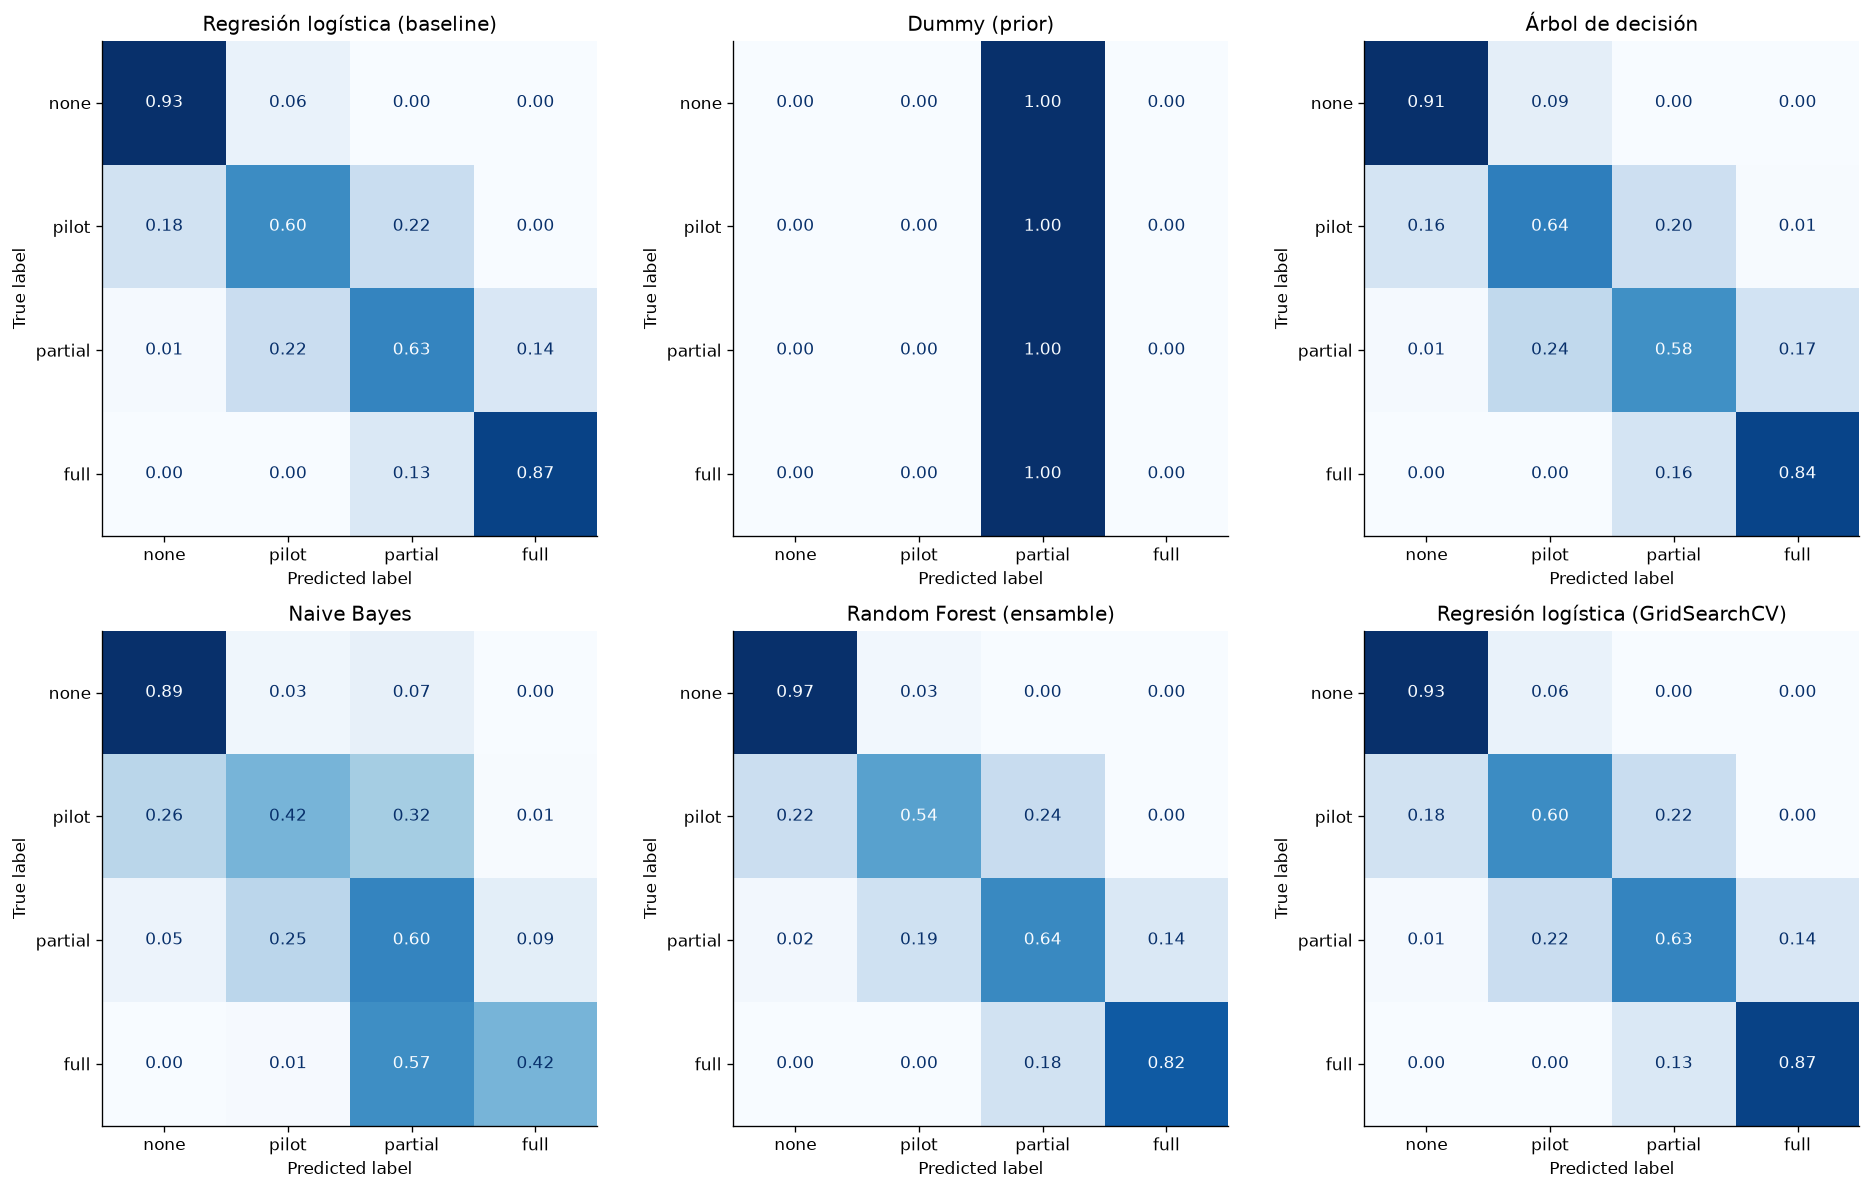

,Predicho no-full,Predicho full
Real no-full,27394,2273
Real full,45,292


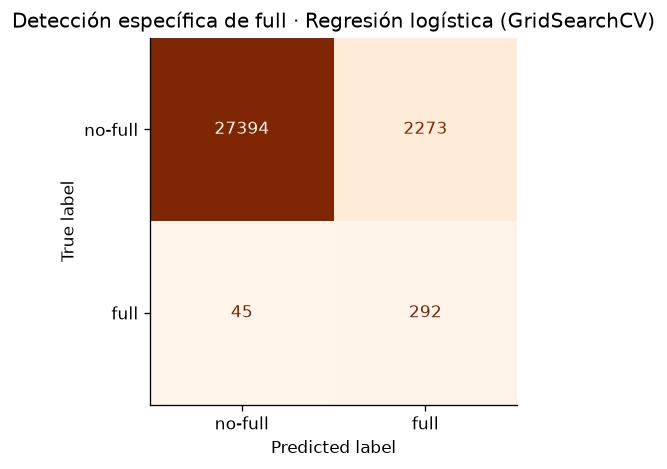

In [9]:
# Matrices de confusión normalizadas por clase para todos los clasificadores.
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (nombre, pred) in zip(axes.flat, predicciones_test.items()):
    cm = confusion_matrix(y_test, pred, labels=orden_etapas, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=orden_etapas).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False
    )
    ax.set_title(nombre)
for ax in axes.flat[len(predicciones_test):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(SALIDAS / "matrices_confusion_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

# Vista binaria específica: detectar la clase rara full frente al resto.
y_full_real = np.asarray(y_test.astype(str) == "full")
y_full_pred = np.asarray(predicciones_test[mejor_clasificador].astype(str) == "full")
cm_full = confusion_matrix(y_full_real, y_full_pred, labels=[False, True])
display(pd.DataFrame(cm_full, index=["Real no-full", "Real full"], columns=["Predicho no-full", "Predicho full"]))
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_full, display_labels=["no-full", "full"]).plot(ax=ax, cmap="Oranges", values_format="d", colorbar=False)
ax.set_title(f"Detección específica de full · {mejor_clasificador}")
plt.tight_layout(); plt.savefig(SALIDAS / "confusion_full_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

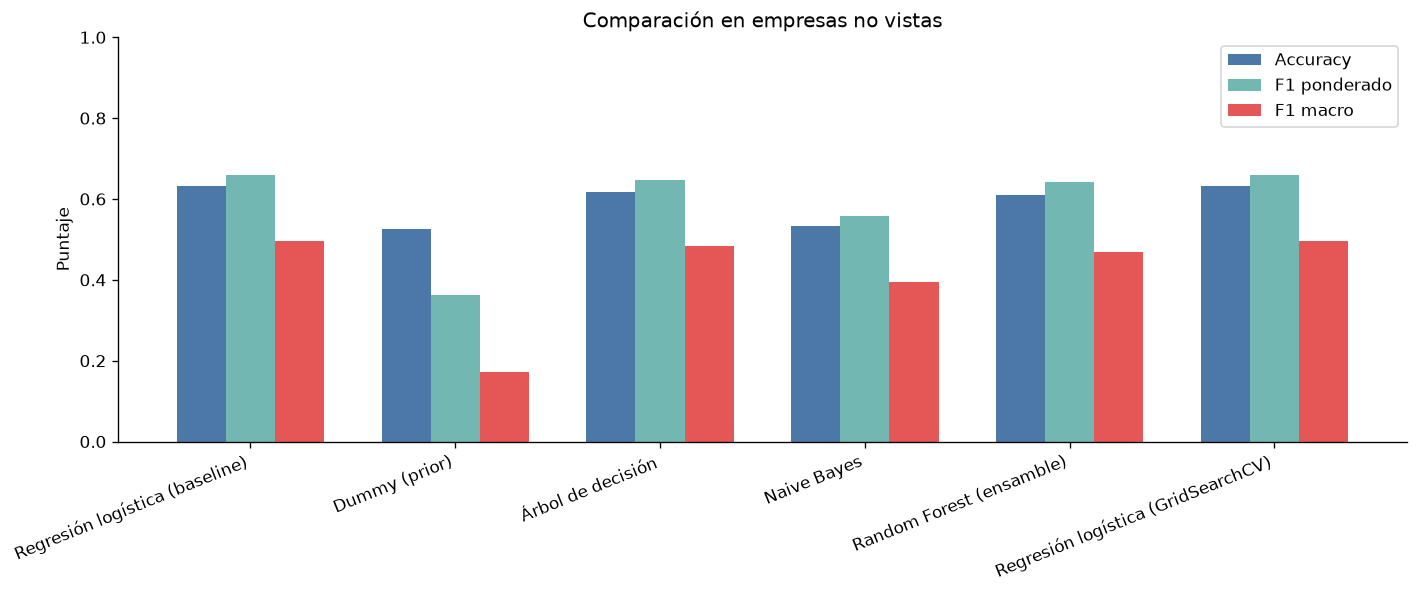

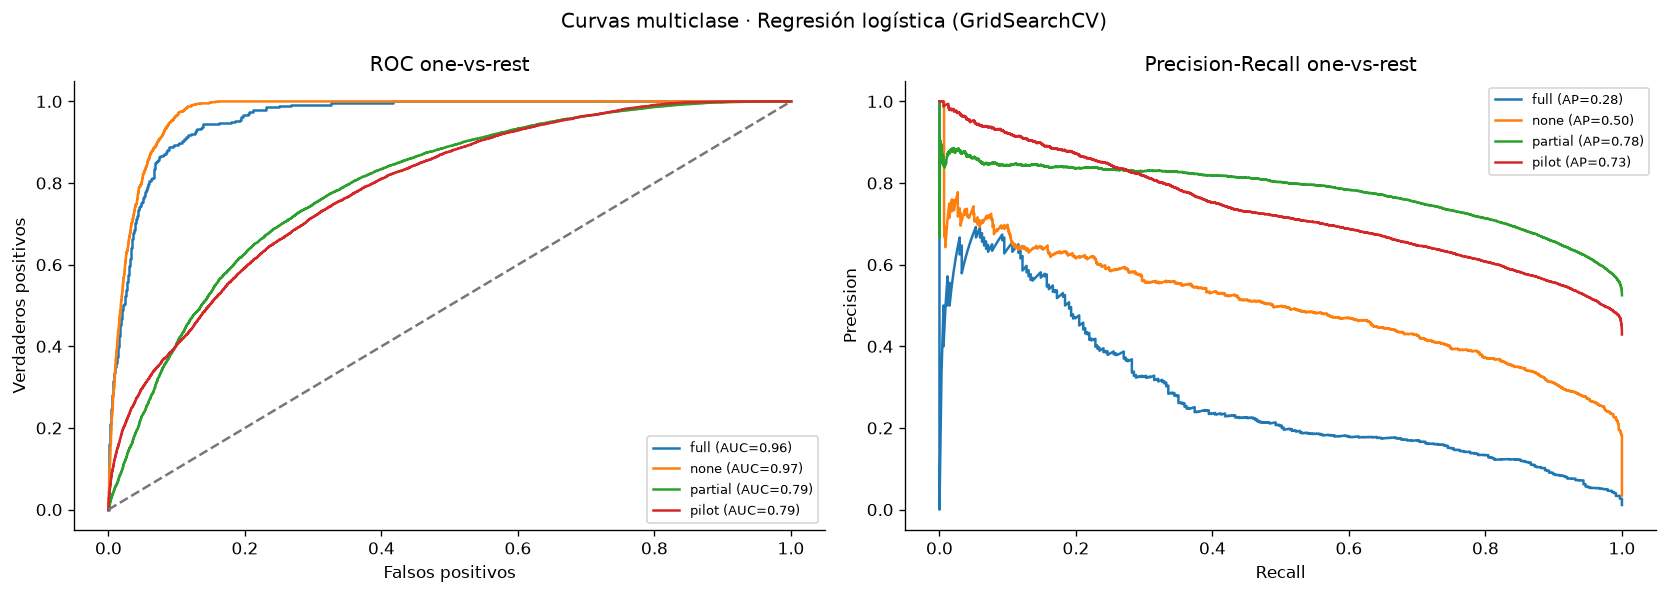

,Variable,Importancia media,Desvío
7,ai_training_hours,0.180099,0.006076
6,num_ai_tools_used,0.093395,0.007912
1,industry,0.008739,0.003874
2,num_employees,0.003746,0.001639
0,country,0.003581,0.005066
3,annual_revenue_usd_millions,0.001761,0.002447
5,survey_year,0.000701,0.001762
4,company_age,-0.000888,0.001017


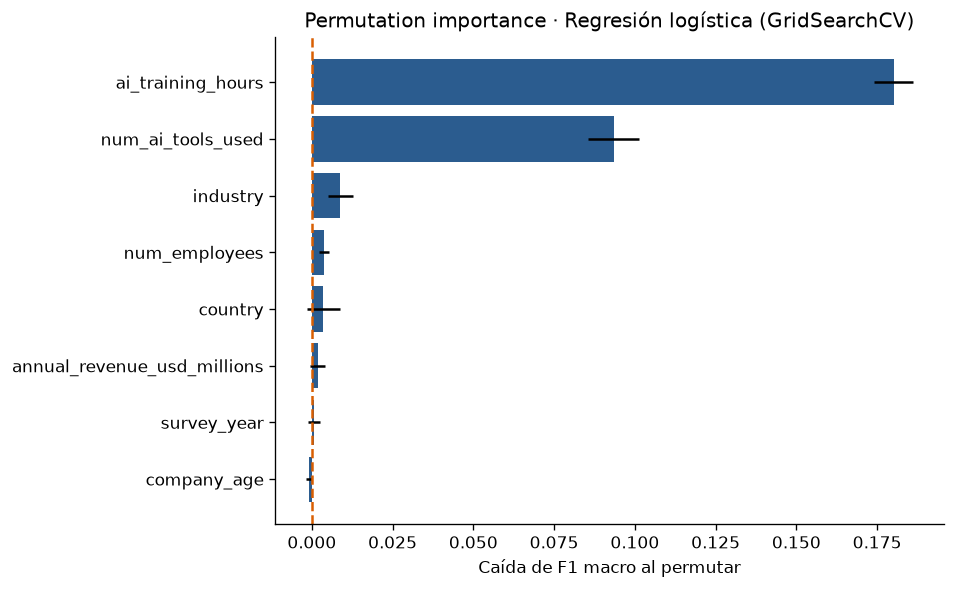

In [10]:
# Métricas comparativas, curvas OVR y permutation importance del mejor modelo por CV.
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_comparativa_tp3)); ancho = 0.24
ax.bar(x-ancho, df_comparativa_tp3["Accuracy (Test)"], ancho, label="Accuracy", color="#4C78A8")
ax.bar(x, df_comparativa_tp3["F1 ponderado (Test)"], ancho, label="F1 ponderado", color="#72B7B2")
ax.bar(x+ancho, df_comparativa_tp3["F1 macro (Test)"], ancho, label="F1 macro", color="#E45756")
ax.set_ylabel("Puntaje"); ax.set_title("Comparación en empresas no vistas")
ax.set_xticks(x, df_comparativa_tp3["Modelo"], rotation=22, ha="right")
ax.set_ylim(0, 1); ax.legend()
plt.tight_layout(); plt.savefig(SALIDAS / "comparativa_metricas_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

# Curvas ROC y Precision-Recall one-vs-rest del clasificador seleccionado por CV.
modelo_curvas = modelos_clasif[mejor_clasificador]
proba_test = modelo_curvas.predict_proba(X_test)
clases_modelo = [str(c) for c in modelo_curvas.classes_]
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5))
for i, clase in enumerate(clases_modelo):
    y_bin = (y_test.astype(str).to_numpy() == clase).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, proba_test[:, i])
    ax_roc.plot(fpr, tpr, label=f"{clase} (AUC={auc(fpr,tpr):.2f})")
    prec, rec, _ = precision_recall_curve(y_bin, proba_test[:, i])
    ap = average_precision_score(y_bin, proba_test[:, i])
    ax_pr.plot(rec, prec, label=f"{clase} (AP={ap:.2f})")
ax_roc.plot([0,1], [0,1], "--", color="#777")
ax_roc.set(xlabel="Falsos positivos", ylabel="Verdaderos positivos", title="ROC one-vs-rest")
ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-Recall one-vs-rest")
for ax in (ax_roc, ax_pr): ax.legend(fontsize=8)
fig.suptitle(f"Curvas multiclase · {mejor_clasificador}")
plt.tight_layout(); plt.savefig(SALIDAS / "curvas_roc_pr_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

# Permutation importance sobre variables originales, no sobre columnas one-hot.
rng_perm = np.random.default_rng(SEMILLA)
idx_perm = rng_perm.choice(len(X_test), size=min(3_000, len(X_test)), replace=False)
perm = permutation_importance(
    modelo_curvas, X_test.iloc[idx_perm], y_test.iloc[idx_perm],
    scoring="f1_macro", n_repeats=4, random_state=SEMILLA, n_jobs=1,
)
imp_perm = pd.DataFrame({"Variable": predictores, "Importancia media": perm.importances_mean, "Desvío": perm.importances_std}).sort_values("Importancia media")
display(imp_perm.sort_values("Importancia media", ascending=False))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp_perm["Variable"], imp_perm["Importancia media"], xerr=imp_perm["Desvío"], color=COLOR_BASE)
ax.axvline(0, color=COLOR_LINEA, linestyle="--")
ax.set(xlabel="Caída de F1 macro al permutar", title=f"Permutation importance · {mejor_clasificador}")
plt.tight_layout(); plt.savefig(SALIDAS / "permutation_importance_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

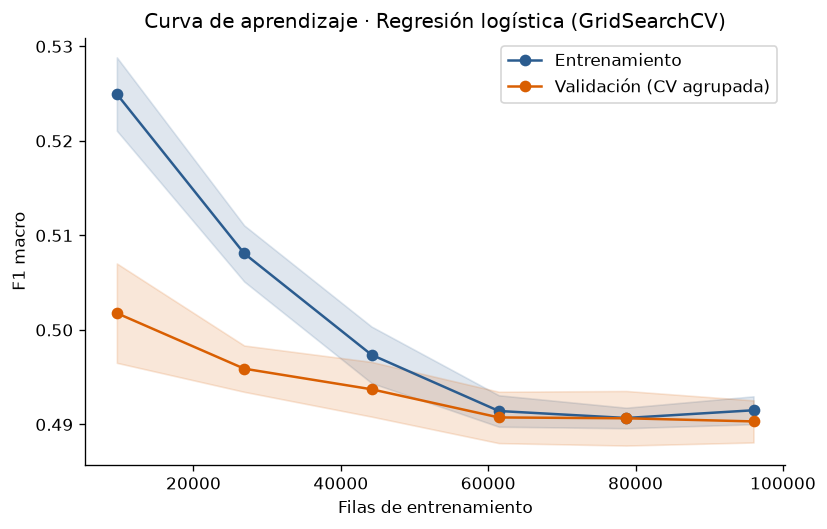

F1 macro con todo el train: entrenamiento 0.492 | validación 0.490


In [11]:
# Curva de aprendizaje del mejor clasificador, con validación agrupada por empresa.
modelo_lc = clone(modelos_clasif[mejor_clasificador])
cv_lc = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA + 1)
tamanios, sc_train, sc_val = learning_curve(
    modelo_lc, X_train, y_train, groups=grupos_train, cv=cv_lc,
    train_sizes=np.linspace(0.1, 1.0, 6), scoring="f1_macro", n_jobs=1,
)
fig, ax = plt.subplots(figsize=(7, 4.5))
for scores, etiqueta, color in [(sc_train, "Entrenamiento", "#2b5c8f"),
                                (sc_val, "Validación (CV agrupada)", "#d95f02")]:
    media, desvio = scores.mean(axis=1), scores.std(axis=1, ddof=1)
    ax.plot(tamanios, media, marker="o", label=etiqueta, color=color)
    ax.fill_between(tamanios, media - desvio, media + desvio, alpha=.15, color=color)
ax.set(xlabel="Filas de entrenamiento", ylabel="F1 macro",
       title=f"Curva de aprendizaje · {mejor_clasificador}")
ax.legend(); plt.tight_layout()
plt.savefig(SALIDAS / "curva_aprendizaje_tp3.png", dpi=250, bbox_inches="tight"); plt.show()
print(f"F1 macro con todo el train: entrenamiento {sc_train[-1].mean():.3f} | validación {sc_val[-1].mean():.3f}")

,Criterio,Umbral,Precision (Test),Recall (Test),F1 (Test),FP (Test),FN (Test)
0,Argmax multiclase (referencia),argmax,0.114,0.866,0.201,2273,45
1,"Umbral binario 0,50",0.5,0.116,0.861,0.205,2202,47
2,Máximo F1 (OOF train),0.916,0.252,0.359,0.296,359,216
3,Máx. precisión con recall ≥ 0.70 (OOF train),0.754,0.176,0.641,0.277,1008,121


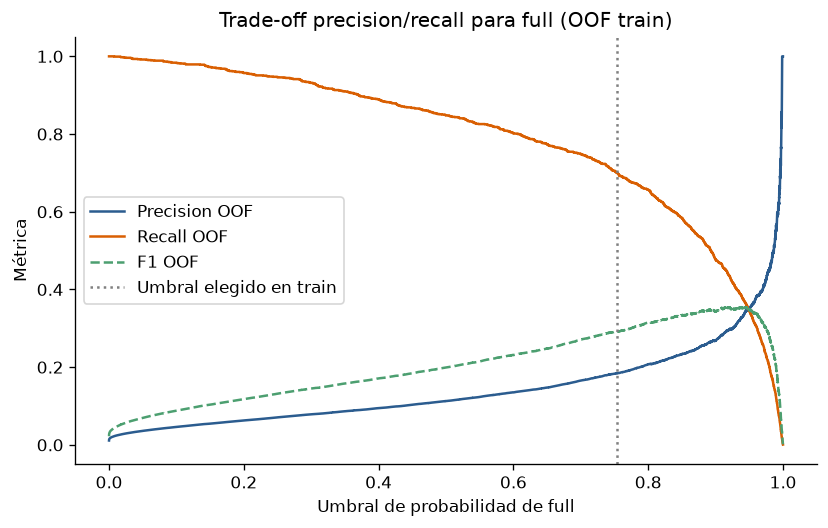

Umbrales escogidos en train OOF y métricas finales calculadas solo en test.


In [12]:
# Elegir el umbral para full con predicciones out-of-fold de train y evaluar en test intacto.
RECALL_MINIMO = 0.70
modelo_umbral = modelos_clasif[mejor_clasificador]
clases_modelo = [str(c) for c in modelo_umbral.classes_]
i_full = clases_modelo.index("full")
proba_oof = cross_val_predict(
    clone(modelo_umbral), X_train, y_train, cv=cv_splits,
    method="predict_proba", n_jobs=1,
)
p_full_oof = proba_oof[:, i_full]
y_full_train = (y_train.astype(str).to_numpy() == "full").astype(int)
prec_oof, rec_oof, umbrales = precision_recall_curve(y_full_train, p_full_oof)
prec_u, rec_u = prec_oof[:-1], rec_oof[:-1]
f1_u = 2 * prec_u * rec_u / np.clip(prec_u + rec_u, 1e-12, None)
i_f1 = int(np.argmax(f1_u))
ok = rec_u >= RECALL_MINIMO
i_dom = int(np.argmax(np.where(ok, prec_u, -1))) if ok.any() else i_f1

p_full_test = modelo_umbral.predict_proba(X_test)[:, i_full]
y_full_test = (y_test.astype(str).to_numpy() == "full").astype(int)
filas_umbral = []
# En clasificación multiclase el modelo usa argmax; eso no equivale al umbral binario p(full) >= 0,50.
pred_argmax = (modelo_umbral.predict(X_test).astype(str) == "full").astype(int)
tn, fp, fn, tp = confusion_matrix(y_full_test, pred_argmax, labels=[0, 1]).ravel()
filas_umbral.append({"Criterio": "Argmax multiclase (referencia)", "Umbral": "argmax",
    "Precision (Test)": round(tp / max(tp + fp, 1), 3),
    "Recall (Test)": round(tp / max(tp + fn, 1), 3),
    "F1 (Test)": round(f1_score(y_full_test, pred_argmax, zero_division=0), 3),
    "FP (Test)": fp, "FN (Test)": fn})
for nombre, umbral in [("Umbral binario 0,50", 0.50),
                       ("Máximo F1 (OOF train)", umbrales[i_f1]),
                       (f"Máx. precisión con recall ≥ {RECALL_MINIMO:.2f} (OOF train)", umbrales[i_dom])]:
    pred = (p_full_test >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_full_test, pred, labels=[0, 1]).ravel()
    filas_umbral.append({"Criterio": nombre, "Umbral": round(float(umbral), 3),
        "Precision (Test)": round(tp / max(tp + fp, 1), 3),
        "Recall (Test)": round(tp / max(tp + fn, 1), 3),
        "F1 (Test)": round(f1_score(y_full_test, pred, zero_division=0), 3),
        "FP (Test)": fp, "FN (Test)": fn})
tabla_umbral = pd.DataFrame(filas_umbral)
display(tabla_umbral)
tabla_umbral.to_csv(SALIDAS / "umbral_full_tp3.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(umbrales, prec_u, label="Precision OOF", color="#2b5c8f")
ax.plot(umbrales, rec_u, label="Recall OOF", color="#d95f02")
ax.plot(umbrales, f1_u, label="F1 OOF", color="#4c9f70", linestyle="--")
ax.axvline(umbrales[i_dom], color="gray", linestyle=":", label="Umbral elegido en train")
ax.set(xlabel="Umbral de probabilidad de full", ylabel="Métrica",
       title="Trade-off precision/recall para full (OOF train)")
ax.legend(); plt.tight_layout()
plt.savefig(SALIDAS / "umbral_full_tp3.png", dpi=250, bbox_inches="tight"); plt.show()
print("Umbrales escogidos en train OOF y métricas finales calculadas solo en test.")

## D.1. Clustering

K-Means se ajusta sin etiquetas y k se elige con criterios internos calculados solo en train. Se contrastan k=2 y k=4 con ARI, NMI y contingencias; los clusters pueden mostrar gradientes de adopción aunque no reproduzcan las cuatro etapas.

,k,Inercia,Silueta,Davies-Bouldin
0,2,94693.5737,0.1699,2.0174
1,3,84785.0367,0.1397,2.1929
2,4,78836.2266,0.1224,2.1378
3,5,74911.9851,0.1178,2.0947
4,6,71724.6224,0.1100,2.0710


Se elige k=2 por la mayor silueta en train; Davies-Bouldin complementa (menor es mejor).


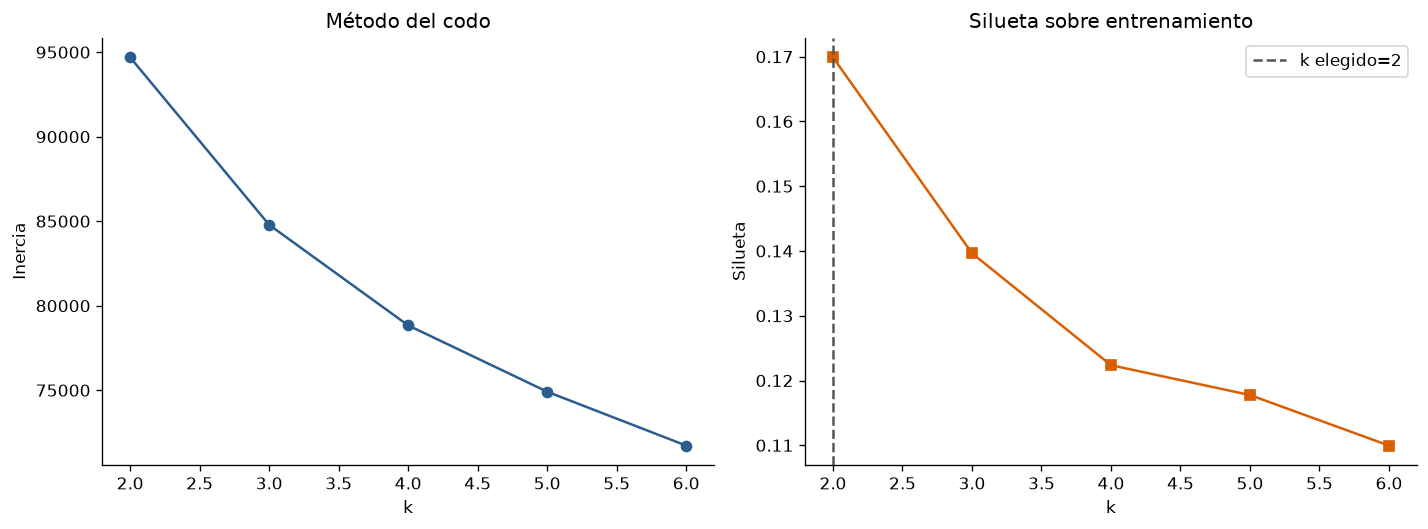

In [13]:
# Seleccionar k con criterios objetivos sobre una muestra de TRAIN, sin consultar las clases.
preprocesador_cluster = crear_preprocesador().fit(X_train)
X_cluster_train = preprocesador_cluster.transform(X_train)
X_cluster_test = preprocesador_cluster.transform(X_test)
rng = np.random.default_rng(SEMILLA)
n_cluster = min(15_000, len(X_cluster_train))
idx_cluster = rng.choice(len(X_cluster_train), size=n_cluster, replace=False)
X_cluster_muestra = X_cluster_train[idx_cluster]
rango_k = range(2, 7)
inercias, siluetas, davies_bouldin = [], [], []
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=5, max_iter=200)
    etiquetas_k = km.fit_predict(X_cluster_muestra)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_cluster_muestra, etiquetas_k, sample_size=min(5_000, len(etiquetas_k)), random_state=SEMILLA))
    davies_bouldin.append(davies_bouldin_score(X_cluster_muestra, etiquetas_k))
k_optimo = list(rango_k)[int(np.argmax(siluetas))]
metricas_k = pd.DataFrame({"k": list(rango_k), "Inercia": inercias, "Silueta": siluetas, "Davies-Bouldin": davies_bouldin})
display(metricas_k.round(4))
print(f"Se elige k={k_optimo} por la mayor silueta en train; Davies-Bouldin complementa (menor es mejor).")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(list(rango_k), inercias, marker="o", color=COLOR_BASE); ax1.set(title="Método del codo", xlabel="k", ylabel="Inercia")
ax2.plot(list(rango_k), siluetas, marker="s", color=COLOR_LINEA); ax2.axvline(k_optimo, linestyle="--", color="#555", label=f"k elegido={k_optimo}")
ax2.set(title="Silueta sobre entrenamiento", xlabel="k", ylabel="Silueta"); ax2.legend()
plt.tight_layout(); plt.savefig(SALIDAS / "seleccion_kmeans_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

,k,ARI vs. clase real,NMI vs. clase real,Silueta train
0,2,0.0526,0.0759,0.1699
1,4,0.0921,0.1115,0.1224


Contingencia k=2 (% por etapa real)


Cluster,Cluster 0,Cluster 1
Etapa real,,
none,3.55,96.45
pilot,19.91,80.09
partial,48.68,51.32
full,70.62,29.38


Contingencia k=4 (% por etapa real)


Cluster,Cluster 0,Cluster 1,Cluster 2,Cluster 3
Etapa real,,,,
none,0.00,2.88,35.83,61.29
pilot,9.11,12.60,34.67,43.62
partial,40.08,24.60,17.62,17.70
full,64.69,34.72,0.30,0.30


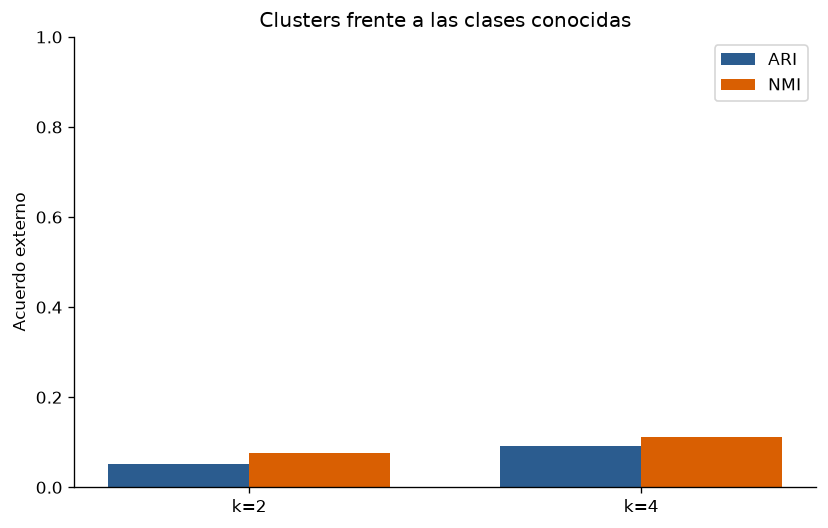

In [14]:
# Comparar explícitamente k=2, k=4 y el óptimo con las clases reales del test.
k_a_comparar = list(dict.fromkeys([2, 4, int(k_optimo)]))
kmeans_por_k, clusters_test_por_k, filas_comparacion_cluster = {}, {}, []
y_test_str = y_test.astype(str).to_numpy()
for k in k_a_comparar:
    km = KMeans(n_clusters=k, random_state=SEMILLA, n_init=10, max_iter=300)
    km.fit(X_cluster_muestra)
    labels_k = km.predict(X_cluster_test)
    kmeans_por_k[k], clusters_test_por_k[k] = km, labels_k
    filas_comparacion_cluster.append({
        "k": k,
        "ARI vs. clase real": adjusted_rand_score(y_test_str, labels_k),
        "NMI vs. clase real": normalized_mutual_info_score(y_test_str, labels_k),
        "Silueta train": metricas_k.loc[metricas_k["k"] == k, "Silueta"].iloc[0],
    })
df_comparacion_cluster = pd.DataFrame(filas_comparacion_cluster).sort_values("k")
display(df_comparacion_cluster.round(4))
df_comparacion_cluster.to_csv(SALIDAS / "comparacion_kmeans_clases_tp3.csv", index=False)
for k_contingencia in [2, 4]:
    df_cruce = pd.DataFrame({"Etapa real": y_test_str,
        "Cluster": [f"Cluster {c}" for c in clusters_test_por_k[k_contingencia]]})
    tabla_contingencia = (pd.crosstab(df_cruce["Etapa real"], df_cruce["Cluster"], normalize="index")
                          .reindex(orden_etapas).fillna(0) * 100)
    print(f"Contingencia k={k_contingencia} (% por etapa real)")
    display(tabla_contingencia.round(2))
    tabla_contingencia.to_csv(SALIDAS / f"contingencia_clustering_k{k_contingencia}_tp3.csv")
clusters_test = clusters_test_por_k[int(k_optimo)]
fig, ax = plt.subplots(figsize=(7, 4.5)); xx = np.arange(len(df_comparacion_cluster)); w=.36
ax.bar(xx-w/2, df_comparacion_cluster["ARI vs. clase real"], w, label="ARI", color=COLOR_BASE)
ax.bar(xx+w/2, df_comparacion_cluster["NMI vs. clase real"], w, label="NMI", color=COLOR_LINEA)
ax.set(xticks=xx, xticklabels=[f"k={k}" for k in df_comparacion_cluster["k"]], ylim=(0,1), ylabel="Acuerdo externo", title="Clusters frente a las clases conocidas")
ax.legend(); plt.tight_layout(); plt.savefig(SALIDAS / "ari_nmi_kmeans_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

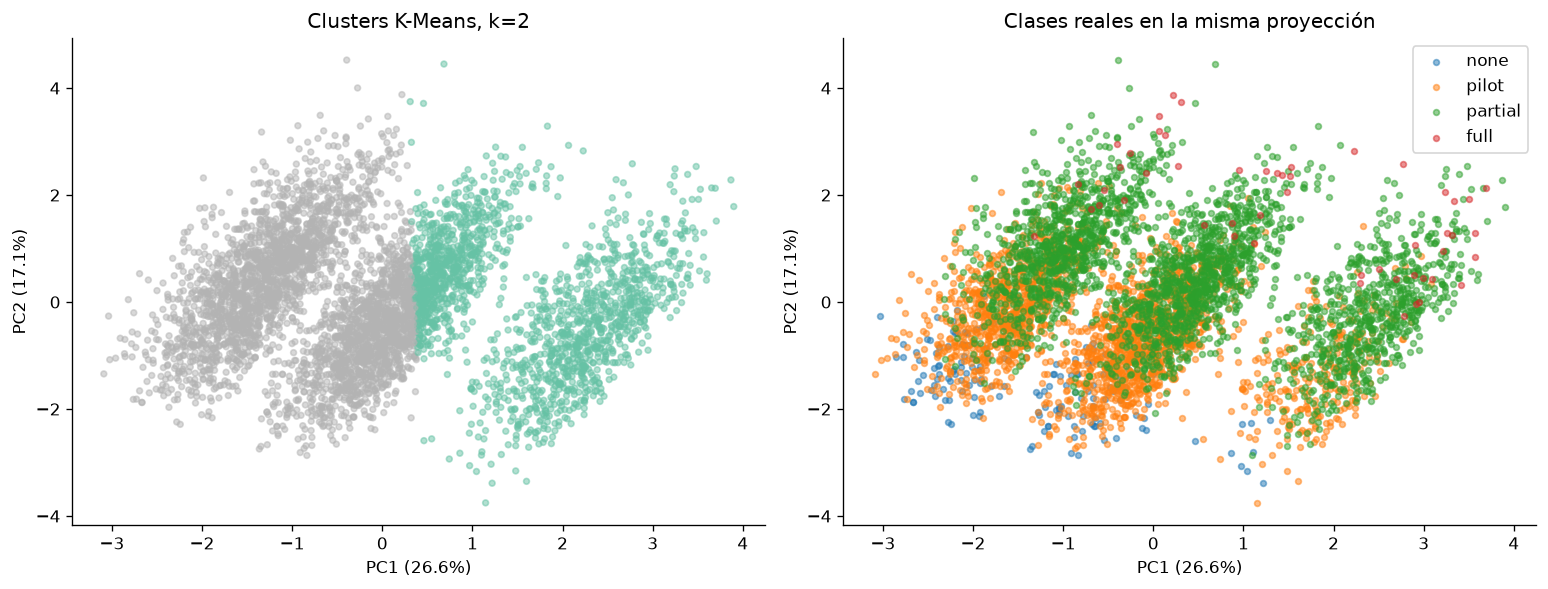

In [15]:
# Visualización PCA del k elegido: un panel coloreado por cluster y otro por clase conocida.
n_pca = min(5_000, len(X_cluster_test))
idx_pca = rng.choice(len(X_cluster_test), size=n_pca, replace=False)
pca = PCA(n_components=2, random_state=SEMILLA).fit(X_cluster_muestra)
X_pca = pca.transform(X_cluster_test[idx_pca])
y_sub_real = y_test.iloc[idx_pca].astype(str).to_numpy()
clusters_sub = clusters_test[idx_pca]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
ax1.scatter(X_pca[:,0], X_pca[:,1], c=clusters_sub, cmap="Set2", alpha=.5, s=12)
ax1.set_title(f"Clusters K-Means, k={k_optimo}"); ax1.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax1.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
for etapa in orden_etapas:
    mask = y_sub_real == etapa
    ax2.scatter(X_pca[mask,0], X_pca[mask,1], label=etapa, alpha=.5, s=12)
ax2.set_title("Clases reales en la misma proyección"); ax2.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)"); ax2.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax2.legend(); plt.tight_layout(); plt.savefig(SALIDAS / "pca_clusters_vs_clases_tp3.png", dpi=250, bbox_inches="tight"); plt.show()

In [16]:
# Persistir el clasificador con mayor F1 macro y casos de prueba de empresas no vistas para Streamlit.
mejores = dict(modelos_clasif)
modelo_clasificacion_seleccionado = mejores[mejor_clasificador]
bundle_clasificacion = {
    "model": modelo_clasificacion_seleccionado,
    "features": predictores,
    "target": target_col,
    "model_name": mejor_clasificador,
    "labels": orden_etapas,
    "category_options": {
        "country": sorted(df["country"].dropna().astype(str).unique().tolist()),
        "industry": sorted(df["industry"].dropna().astype(str).unique().tolist()),
    },
}
joblib.dump(bundle_clasificacion, SALIDAS / "modelo_clasificacion_tp3.joblib")
filas_test = df.iloc[test_idx].copy()
demo_clas = (filas_test.groupby(target_col, observed=True, group_keys=False)
             .head(3).copy().reset_index(drop=True))
demo_clas.insert(0, "demo_id", [f"CLA-{i:02d}" for i in range(1, len(demo_clas)+1)])
demo_clas[["demo_id", "company_id", *predictores, target_col]].to_csv(
    SALIDAS / "muestras_prueba_clasificacion.csv", index=False
)
print(f"Guardado {mejor_clasificador} y {len(demo_clas)} muestras reservadas del test.")

Guardado Regresión logística (GridSearchCV) y 12 muestras reservadas del test.


## Interpretación de resultados

La regresión logística ajustada fue la mejor por F1 macro en validación agrupada (0,490 ± 0,002) y obtuvo F1 macro 0,495, Kappa 0,398 y accuracy 0,632 en empresas reservadas. El ajuste C=10 mejoró apenas 0,0003 de F1 macro frente a C=1. Random Forest quedó por debajo (F1 macro 0,475 en CV y 0,470 en test) y tardó 3,66 s por fold, frente a 1,38 s de la logística.

**Precisión y recall de full.** Con la decisión multiclase argmax, la logística detectó 292 de 337 casos full (recall 0,87), con precisión 0,11: clasificó como full a 2.273 casos no-full. El umbral elegido en predicciones out-of-fold de train fue 0,754. En test alcanzó precisión 0,176 y recall 0,641, con 1.008 falsos positivos y 121 falsos negativos. La mejora de precisión reduce el recall y no alcanza en test el objetivo de 0,70 definido en train. El umbral binario 0,50 no equivale a argmax multiclase; la tabla muestra ambas referencias.

**Ajuste.** La brecha F1 macro train-test fue −0,004 en logística y 0,003 en el árbol; no se observa una brecha compatible con sobreajuste marcado. El F1 macro cercano a 0,5 y la ablación de contexto (0,185 frente a 0,495 al incluir señales de comportamiento) sugieren que la información predictiva depende mucho de herramientas usadas y capacitación. Esto limita la interpretación como predicción prospectiva y no demuestra por sí solo subajuste.

**Desbalance.** none representa 3,47 % y full 1,12 % de las filas; el accuracy de 0,63 oculta diferencias importantes. class_weight=balanced sube el recall de clases raras a costa de precisión: para none, recall 0,93 y precisión 0,28; para full, recall 0,87 y precisión 0,11. Por eso la selección y la discusión usan F1 macro y métricas por clase, no accuracy aislada.

K-Means mostró gradientes, no una recuperación exacta de las etiquetas: ARI/NMI fueron 0,053/0,076 para k=2 y 0,092/0,112 para k=4. Con k=2, 96,4 % de none cayó en un cluster y 70,6 % de full en el otro; k=4 separa parcialmente los extremos, pero las etapas intermedias se solapan entre grupos. Estos resultados describen este dataset y no implican causalidad ni desempeño futuro.

## Limitaciones

La fuente no documenta cómo se generaron las observaciones. Además, la etapa objetivo se construye por tramos a partir de una tasa continua y las clases tienen tamaños distintos. El rendimiento describe este archivo y la separación de empresas empleada; no demuestra que las mismas tasas de error se mantengan en otra población. La selección final usa F1 macro, pero la elección puede variar si el costo de falsos negativos o falsos positivos cambia en la aplicación.